In [1]:
import pandas as pd
import numpy as np

## Data Preprocessing

This project uses a Sri Lankan vehicle price dataset to develop and compare ensemble learning regression models.

The dataset contains 9,788 records and 17 columns, including vehicle brand, model, year of manufacture, engine capacity, fuel type, mileage, and price.

The dataset was loaded using the Pandas library for further preprocessing, exploratory data analysis, and machine learning model development.

In [3]:
df = pd.read_csv("car_price_dataset.csv")

In [4]:
df.head()

,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [5]:
df.shape

(9788, 17)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9788 entries, 0 to 9787
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      9788 non-null   int64  
 1   Brand           9788 non-null   object 
 2   Model           9788 non-null   object 
 3   YOM             9788 non-null   int64  
 4   Engine (cc)     9788 non-null   float64
 5   Gear            9788 non-null   object 
 6   Fuel Type       9788 non-null   object 
 7   Millage(KM)     9788 non-null   float64
 8   Town            9788 non-null   object 
 9   Date            9788 non-null   object 
 10  Leasing         9788 non-null   object 
 11  Condition       9788 non-null   object 
 12  AIR CONDITION   9788 non-null   object 
 13  POWER STEERING  9788 non-null   object 
 14  POWER MIRROR    9788 non-null   object 
 15  POWER WINDOW    9788 non-null   object 
 16  Price           9788 non-null   float64
dtypes: float64(3), int64(2), object(1

The dataset contains 9,788 vehicle records and 17 columns.

In [7]:
df.describe()

,Unnamed: 0,YOM,Engine (cc),Millage(KM),Price
count,9788.000000,9788.000000,9788.000000,9788.000000,9788.000000
mean,4893.758991,2006.759093,1260.442358,200649.979567,53.464275
std,2826.028988,9.831574,403.769059,108147.314860,43.625049
min,0.000000,1956.000000,573.000000,11000.000000,2.650000
25%,2446.750000,2001.000000,1000.000000,110000.000000,26.250000
50%,4893.500000,2009.000000,1300.000000,176000.000000,43.000000
75%,7341.250000,2015.000000,1500.000000,264000.000000,69.750000
max,9788.000000,2024.000000,4800.000000,759000.000000,790.000000


In [8]:
df.isnull().sum()

Unnamed: 0        0
Brand             0
Model             0
YOM               0
Engine (cc)       0
Gear              0
Fuel Type         0
Millage(KM)       0
Town              0
Date              0
Leasing           0
Condition         0
AIR CONDITION     0
POWER STEERING    0
POWER MIRROR      0
POWER WINDOW      0
Price             0
dtype: int64

In [9]:
df.select_dtypes(include=['object']).columns

Index(['Brand', 'Model', 'Gear', 'Fuel Type', 'Town', 'Date', 'Leasing',
       'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR',
       'POWER WINDOW'],
      dtype='object')

In [10]:
df.select_dtypes(include=['number']).columns

Index(['Unnamed: 0', 'YOM', 'Engine (cc)', 'Millage(KM)', 'Price'], dtype='object')

In [11]:
df['Brand'].value_counts().head(10)

Brand
TOYOTA           3089
SUZUKI           2473
NISSAN           1248
HONDA             681
MITSUBISHI        284
PERODUA           257
MICRO             244
HYUNDAI           189
MAZDA             181
MERCEDES-BENZ     168
Name: count, dtype: int64

The features include numerical variables such as year of manufacture, engine capacity, and mileage, as well as categorical variables such as brand, model, transmission type, fuel type, and town.

The target variable is `Price`, making this a supervised machine learning regression problem.

Initial inspection shows no missing values in the dataset. Further preprocessing and exploratory data analysis will be performed to identify duplicate records, potential outliers, and categorical encoding requirements.

In [12]:
df.duplicated().sum()

0

In [13]:
df = df.drop(columns=['Unnamed: 0'])

In [14]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 18


In [15]:
df = df.drop_duplicates()

In [16]:
print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (9770, 16)


Duplicate records were identified and removed to improve data quality and avoid unnecessary repetition during model training.

The unnecessary index column was removed before checking for duplicates. This helps ensure that identical vehicle records are not treated as unique observations simply because they have different row indices.

Removing duplicate records helps reduce potential bias in model training and evaluation.

In [17]:
print("Invalid Manufacturing Years:",
      (df['YOM'] < 1950).sum())

Invalid Manufacturing Years: 0


In [18]:
print("Invalid Engine Capacities:",
      (df['Engine (cc)'] <= 0).sum())
print("Invalid Mileage Values:",
      (df['Millage(KM)'] < 0).sum())

print("Invalid Prices:",
      (df['Price'] <= 0).sum())

Invalid Engine Capacities: 0
Invalid Mileage Values: 0
Invalid Prices: 0


The dataset was examined for invalid numerical values in key features, including manufacturing year, engine capacity, mileage, and vehicle price.

Validation conditions were applied to identify negative mileage, non-positive engine capacities, non-positive prices, and manufacturing years outside the selected review threshold.

These checks help identify potential data-quality issues before model training. Unusual values will be investigated further during exploratory data analysis.

# Detect Outliers in Numerical Features

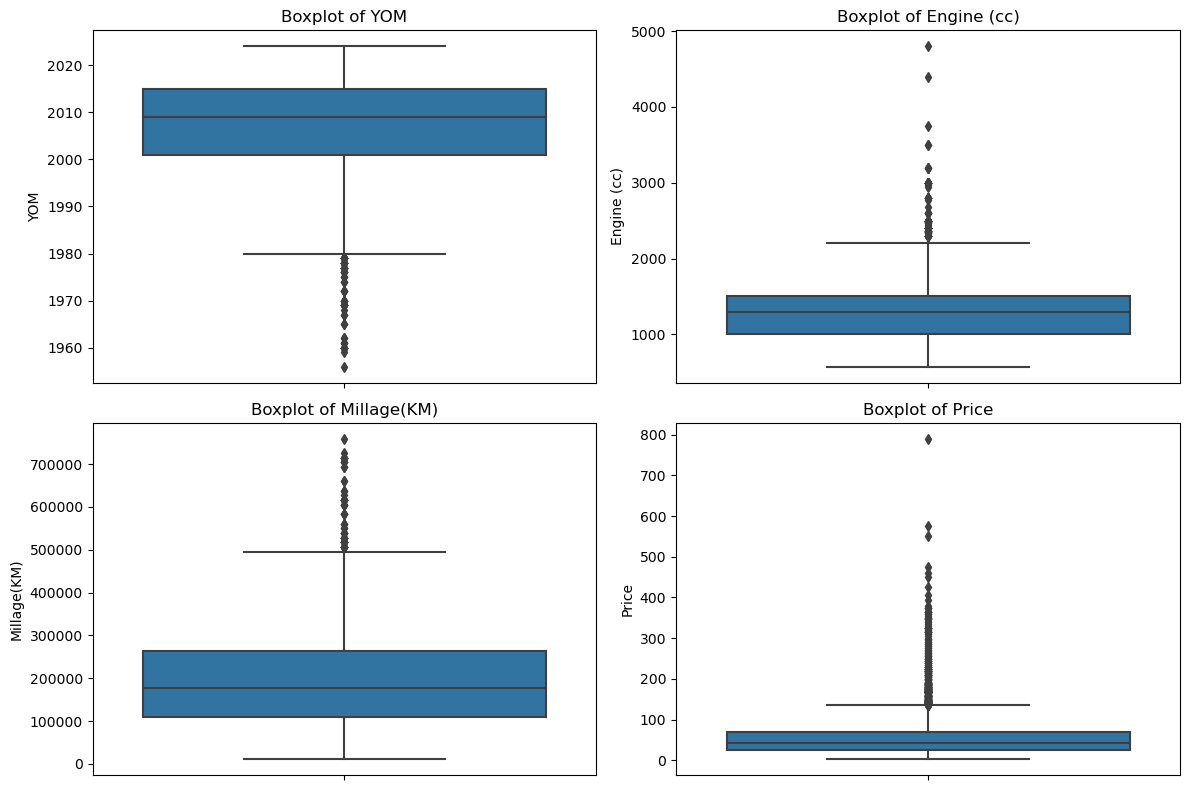

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = [
    'YOM',
    'Engine (cc)',
    'Millage(KM)',
    'Price'
]

plt.figure(figsize=(12, 8))

for i, column in enumerate(numerical_columns):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()

Boxplots were generated for the numerical features: Year of Manufacture (YOM), Engine Capacity, Mileage, and Price.

Boxplots help visualize data distributions and identify potential outliers based on the interquartile range (IQR).

Outliers may represent unusual vehicle characteristics, such as high mileage or expensive luxury vehicles. Therefore, potential outliers were identified visually without immediately removing them, as they may represent valid observations.

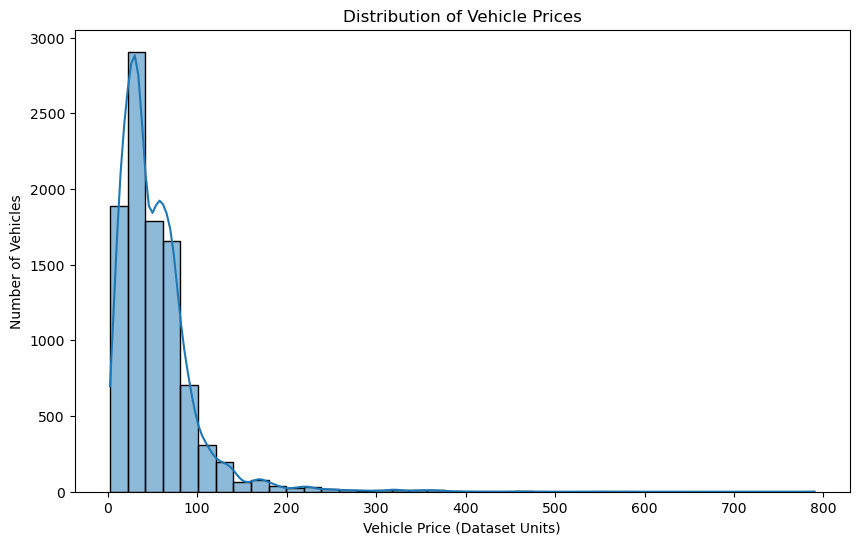

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='Price',
    bins=40,
    kde=True
)

plt.title('Distribution of Vehicle Prices')
plt.xlabel('Vehicle Price (Dataset Units)')
plt.ylabel('Number of Vehicles')

plt.show()

In [21]:
print("Price Skewness:", df['Price'].skew())

Price Skewness: 3.4614515778471717


                  YOM  Engine (cc)  Millage(KM)     Price
YOM          1.000000    -0.405839    -1.000000  0.507217
Engine (cc) -0.405839     1.000000     0.405839  0.193197
Millage(KM) -1.000000     0.405839     1.000000 -0.507217
Price        0.507217     0.193197    -0.507217  1.000000


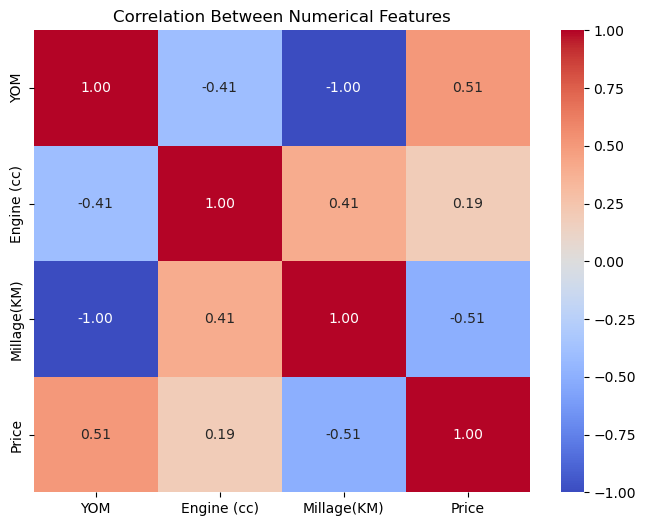

In [22]:
numerical_features = [
    'YOM',
    'Engine (cc)',
    'Millage(KM)',
    'Price'
]

correlation_matrix = df[numerical_features].corr()

print(correlation_matrix)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Features')
plt.show()

Brand
MERCEDES-BENZ    156.500769
HONDA             76.476568
TOYOTA            67.296782
SUZUKI            44.217243
PERODUA           42.244169
MAZDA             35.281354
NISSAN            30.708748
HYUNDAI           28.996224
MICRO             28.051563
MITSUBISHI        26.218415
Name: Price, dtype: float64


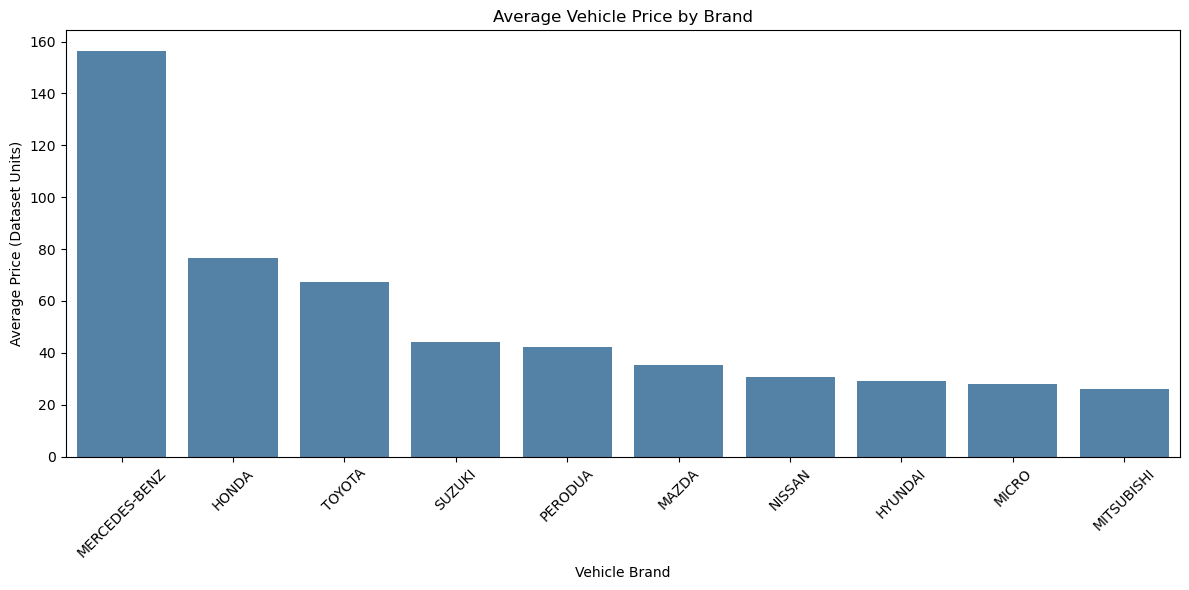

In [23]:
top_brands = df['Brand'].value_counts().head(10).index

top_brands_df = df[df['Brand'].isin(top_brands)]

average_prices = (
    top_brands_df.groupby('Brand')['Price']
    .mean()
    .sort_values(ascending=False)
)

print(average_prices)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=average_prices.index,
    y=average_prices.values,
    color='steelblue'
)

plt.title('Average Vehicle Price by Brand')
plt.xlabel('Vehicle Brand')
plt.ylabel('Average Price (Dataset Units)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Fuel Type
Petrol      7850
Hybrid      1237
Diesel       614
Electric      69
Name: count, dtype: int64

Average Price by Fuel Type:
Fuel Type
Hybrid      82.676146
Electric    81.425900
Petrol      49.610449
Diesel      40.560163
Name: Price, dtype: float64


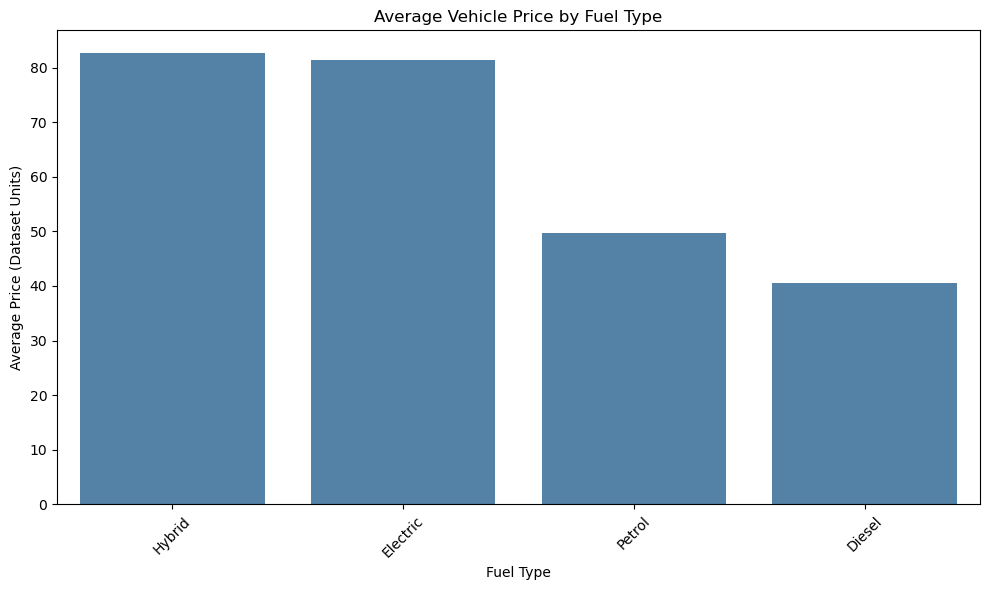

In [24]:
print(df['Fuel Type'].value_counts())

fuel_prices = (
    df.groupby('Fuel Type')['Price']
    .mean()
    .sort_values(ascending=False)
)

print("\nAverage Price by Fuel Type:")
print(fuel_prices)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=fuel_prices.index,
    y=fuel_prices.values,
    color='steelblue'
)

plt.title('Average Vehicle Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Price (Dataset Units)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

YOM
1956     40.000000
1959     24.000000
1960     23.151563
1961     25.166667
1962     39.500000
           ...    
2020    122.934615
2021     35.850000
2022     46.380000
2023    104.850000
2024    177.014667
Name: Price, Length: 62, dtype: float64


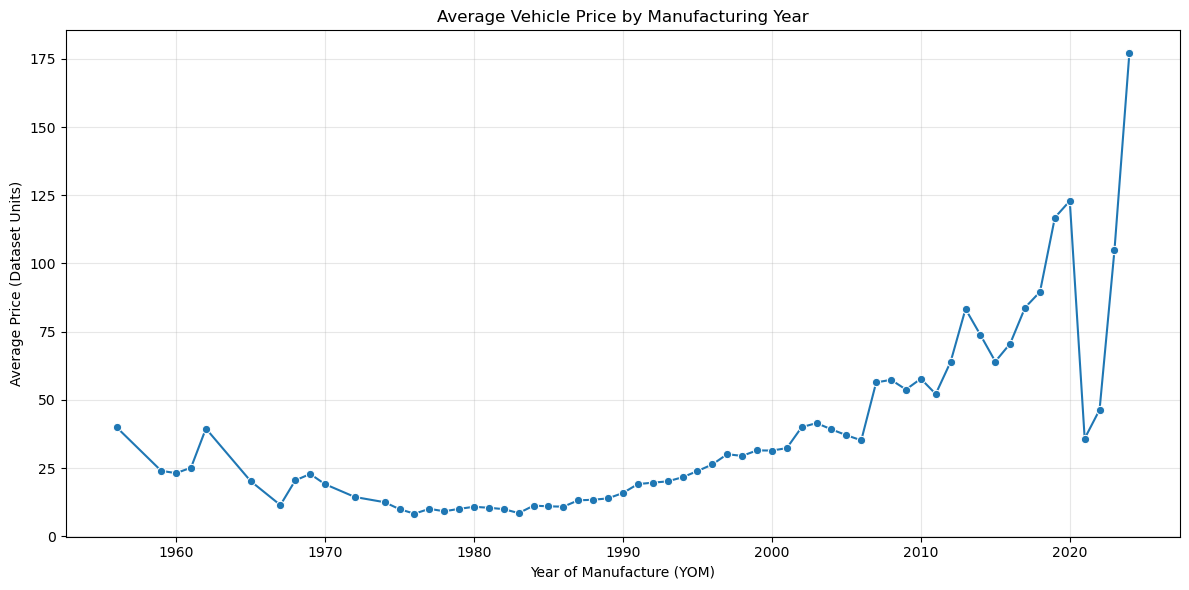

In [25]:
year_prices = (
    df.groupby('YOM')['Price']
    .mean()
    .sort_index()
)

print(year_prices)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=year_prices.index,
    y=year_prices.values,
    marker='o'
)

plt.title('Average Vehicle Price by Manufacturing Year')
plt.xlabel('Year of Manufacture (YOM)')
plt.ylabel('Average Price (Dataset Units)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Feature and Target Variable Selection

The dataset was divided into independent features (X) and the dependent target variable (y) to prepare it for supervised machine learning.

The target variable, Price, represents the vehicle price to be predicted.

The independent features include vehicle characteristics such as brand, model, manufacturing year, engine capacity, transmission type, fuel type, mileage, and vehicle condition.

The listing date was excluded from the initial feature set to focus the prediction model on vehicle-specific characteristics.

This separation prepares the dataset for the next stages of preprocessing and ensemble regression model training.

In [26]:
X = df.drop(columns=['Price', 'Date'])

y = df['Price']

print("Features (X):")
display(X.head())

print("Target (y):")
display(y.head())

print("X Shape:", X.shape)
print("y Shape:", y.shape)


Features (X):


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW
0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,No Leasing,USED,Available,Available,Available,Available
1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,No Leasing,USED,Available,Available,Available,Available
2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,No Leasing,USED,Available,Available,Available,Available
3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,No Leasing,USED,Available,Available,Available,Available
4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,No Leasing,USED,Available,Available,Available,Available


Target (y):


0    100.0
1     97.0
2     98.5
3    107.0
4     99.5
Name: Price, dtype: float64

X Shape: (9770, 14)
y Shape: (9770,)


In [27]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (7816, 14)
X_test shape: (1954, 14)
y_train shape: (7816,)
y_test shape: (1954,)


In [28]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_columns = X_train.select_dtypes(
    include=['object']
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    include=['number']
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_columns
        ),
        (
            'num',
            'passthrough',
            numerical_columns
        )
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("\nEncoded Training Shape:",
      X_train_encoded.shape)

print("Encoded Testing Shape:",
      X_test_encoded.shape)

Categorical Columns:
['Brand', 'Model', 'Gear', 'Fuel Type', 'Town', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']

Numerical Columns:
['YOM', 'Engine (cc)', 'Millage(KM)']

Encoded Training Shape: (7816, 1529)
Encoded Testing Shape: (1954, 1529)


# Feature Scaling

Feature scaling was performed using the StandardScaler technique to standardize numerical features such as manufacturing year, engine capacity, and mileage.

A ColumnTransformer was used to combine StandardScaler for numerical features and One-Hot Encoding for categorical features.

The preprocessing transformer was fitted only on the training dataset to prevent data leakage, and the same transformations were applied to the testing dataset.

Although tree-based ensemble algorithms are generally insensitive to feature scaling, standardization can improve the performance of distance-based and regularized models used in Stacking.

This step prepares the input features for ensemble learning model development.

from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_columns
        ),
        (
            'num',
            StandardScaler(),
            numerical_columns
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:",
      X_train_processed.shape)

print("Processed Testing Shape:",
      X_test_processed.shape)

# Bagging Using Random Forest Regressor

In [30]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)

print("First 5 Predicted Prices:")
print(rf_predictions[:5])

print("\nFirst 5 Actual Prices:")
print(y_test.iloc[:5].values)

First 5 Predicted Prices:
[283.7715      34.37973214   7.5922     211.8925      32.11092778]

First 5 Actual Prices:
[375.          35.04761905  11.75       119.5         36.5       ]


In [31]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

rf_mae = mean_absolute_error(
    y_test, rf_predictions
)

rf_rmse = np.sqrt(mean_squared_error(
    y_test, rf_predictions
))

rf_r2 = r2_score(
    y_test, rf_predictions
)

print("Random Forest Model Evaluation")
print("------------------------------")
print(f"MAE  : {rf_mae:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R²   : {rf_r2:.4f}")

Random Forest Model Evaluation
------------------------------
MAE  : 5.5183
RMSE : 21.6465
R²   : 0.8027


## Interpretation of Random Forest Results

The Random Forest Regressor achieved a Mean Absolute Error (MAE) of 5.5183, a Root Mean Squared Error (RMSE) of 21.6465, and an R² Score of 0.8027 on the testing dataset.

The R² Score indicates that the model explains approximately 80.27% of the variation in vehicle prices relative to the test-set mean baseline.

The difference between MAE and RMSE suggests that some predictions may have relatively large errors.

Overall, Random Forest provides a useful baseline for evaluating the performance of the other ensemble learning approaches.

# Boosting Using Gradient Boosting Regressor

In [32]:

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

gb_predictions = gb_model.predict(X_test_processed)

print("First 5 Predicted Prices:")
print(gb_predictions[:5])

print("\nFirst 5 Actual Prices:")
print(y_test.iloc[:5].values)

First 5 Predicted Prices:
[278.94949107  33.24125314  11.77348524 179.4763061   36.1149225 ]

First 5 Actual Prices:
[375.          35.04761905  11.75       119.5         36.5       ]


In [33]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

gb_mae = mean_absolute_error(
    y_test, gb_predictions
)

gb_rmse = np.sqrt(mean_squared_error(
    y_test, gb_predictions
))

gb_r2 = r2_score(
    y_test, gb_predictions
)

print("Gradient Boosting Model Evaluation")
print("----------------------------------")
print(f"MAE  : {gb_mae:.4f}")
print(f"RMSE : {gb_rmse:.4f}")
print(f"R²   : {gb_r2:.4f}")

Gradient Boosting Model Evaluation
----------------------------------
MAE  : 9.1663
RMSE : 23.9049
R²   : 0.7594


## Compare Random Forest and Gradient Boosting Performance

In [34]:
comparison_df = pd.DataFrame({
    'Model': [
        'Random Forest (Bagging)',
        'Gradient Boosting (Boosting)'
    ],
    'MAE': [rf_mae, gb_mae],
    'RMSE': [rf_rmse, gb_rmse],
    'R2 Score': [rf_r2, gb_r2]
})

display(comparison_df.round(4))

best_model = comparison_df.loc[
    comparison_df['RMSE'].idxmin(), 'Model'
]

print("\nBest Model (Based on RMSE):", best_model)

,Model,MAE,RMSE,R2 Score
0,Random Forest (Bagging),5.5183,21.6465,0.8027
1,Gradient Boosting (Boosting),9.1663,23.9049,0.7594



Best Model (Based on RMSE): Random Forest (Bagging)


### Comparison of Bagging and Boosting Models

The performance of Random Forest (Bagging) and Gradient Boosting (Boosting) was compared using MAE, RMSE, and R² Score.

Random Forest achieved an MAE of 5.5183, RMSE of 21.6465, and R² Score of 0.8027.

Gradient Boosting achieved an MAE of 9.1663, RMSE of 23.9049, and R² Score of 0.7594.

Random Forest outperformed Gradient Boosting across all three evaluation metrics on the testing dataset.

The results suggest that Random Forest provides better predictive performance for this dataset under the current experimental settings. However, further evaluation and hyperparameter optimization may improve both models.

The next stage will implement Stacking to investigate whether combining multiple regression algorithms can further improve prediction accuracy.

# Stacking Ensemble Learning

In [38]:

import os

os.environ["LOKY_MAX_CPU_COUNT"] = "2"

print("CPU configuration updated successfully!")


CPU configuration updated successfully!


In [37]:

from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge

# Define the base models
base_models = [
    ('rf', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )),

    ('gb', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )),

    ('knn', KNeighborsRegressor(
        n_neighbors=5
    ))
]

stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(),
    cv=5,
    n_jobs=-1
)

stacking_model.fit(X_train_processed, y_train)

stacking_predictions = stacking_model.predict(
    X_test_processed
)

print("First 5 Stacking Predictions:")
print(stacking_predictions[:5])

print("\nFirst 5 Actual Prices:")
print(y_test.iloc[:5].values)

First 5 Stacking Predictions:
[278.10459314  33.99867948   6.29643873 215.38655243  31.94795924]

First 5 Actual Prices:
[375.          35.04761905  11.75       119.5         36.5       ]


In [39]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

stacking_mae = mean_absolute_error(
    y_test, stacking_predictions
)

stacking_rmse = np.sqrt(mean_squared_error(
    y_test, stacking_predictions
))

stacking_r2 = r2_score(
    y_test, stacking_predictions
)

print("Stacking Model Evaluation")
print("-------------------------")
print(f"MAE  : {stacking_mae:.4f}")
print(f"RMSE : {stacking_rmse:.4f}")
print(f"R²   : {stacking_r2:.4f}")


Stacking Model Evaluation
-------------------------
MAE  : 5.7400
RMSE : 21.4913
R²   : 0.8055


# Compare Bagging, Boosting, and Stacking Models

In [40]:
comparison_df = pd.DataFrame({
    'Model': [
        'Random Forest (Bagging)',
        'Gradient Boosting (Boosting)',
        'Stacking Regressor'
    ],
    'MAE': [rf_mae, gb_mae, stacking_mae],
    'RMSE': [rf_rmse, gb_rmse, stacking_rmse],
    'R2 Score': [rf_r2, gb_r2, stacking_r2]
})

comparison_df = comparison_df.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

display(comparison_df.round(4))

best_model_name = comparison_df.loc[0, 'Model']

print("Best Model Based on RMSE:", best_model_name)

,Model,MAE,RMSE,R2 Score
0,Stacking Regressor,5.7400,21.4913,0.8055
1,Random Forest (Bagging),5.5183,21.6465,0.8027
2,Gradient Boosting (Boosting),9.1663,23.9049,0.7594


Best Model Based on RMSE: Stacking Regressor


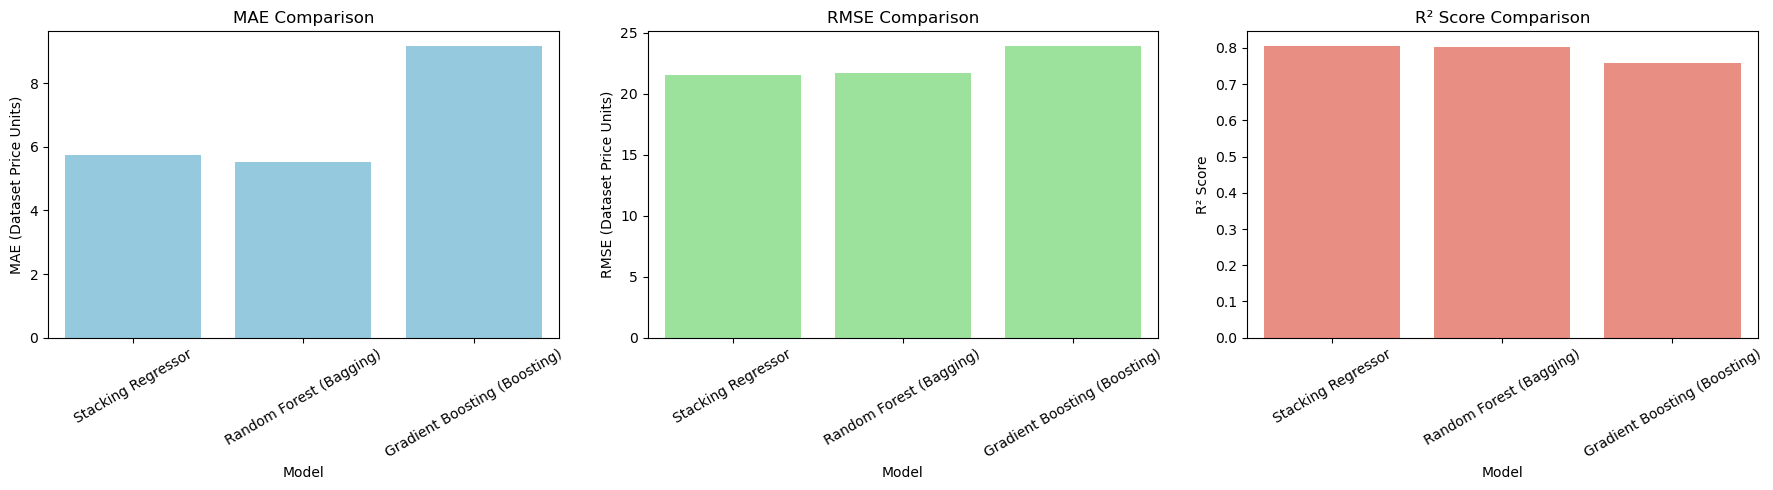

In [41]:
# Create three comparison charts
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE comparison
sns.barplot(
    data=comparison_df,
    x='Model',
    y='MAE',
    ax=axes[0],
    color='skyblue'
)
axes[0].set_title('MAE Comparison')
axes[0].set_ylabel('MAE (Dataset Price Units)')
axes[0].tick_params(axis='x', rotation=30)

# RMSE comparison
sns.barplot(
    data=comparison_df,
    x='Model',
    y='RMSE',
    ax=axes[1],
    color='lightgreen'
)
axes[1].set_title('RMSE Comparison')
axes[1].set_ylabel('RMSE (Dataset Price Units)')
axes[1].tick_params(axis='x', rotation=30)

# R² Score comparison
sns.barplot(
    data=comparison_df,
    x='Model',
    y='R2 Score',
    ax=axes[2],
    color='salmon'
)
axes[2].set_title('R² Score Comparison')
axes[2].set_ylabel('R² Score')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### Visualization of Ensemble Model Performance

The performance of the three ensemble learning models was visualized using bar charts comparing MAE, RMSE, and R² Score.

The Stacking Regressor achieved the lowest RMSE (21.4913) and highest R² Score (0.8055), demonstrating slightly better predictive performance according to these metrics.

Random Forest achieved the lowest MAE (5.5183), indicating the smallest average absolute prediction error.

Gradient Boosting performed less effectively than the other two models under the current configurations.

The visual comparison demonstrates that Stacking offers a small improvement in RMSE and R² over Random Forest, while Random Forest remains competitive in average prediction accuracy.

# Comparison of Ensemble Learning Models

Three ensemble learning techniques were implemented and evaluated for predicting used vehicle prices in Sri Lanka: Random Forest (Bagging), Gradient Boosting (Boosting), and Stacking.

The Stacking Regressor achieved the lowest RMSE of 21.4913 and the highest R² Score of 0.8055, indicating the best performance according to these two evaluation metrics.

Random Forest achieved the lowest MAE of 5.5183, demonstrating better average absolute prediction accuracy than the other models.

Gradient Boosting achieved an RMSE of 23.9049 and an R² Score of 0.7594, performing less effectively under the current experimental settings.

Overall, Stacking demonstrated a slight advantage in RMSE and R², while Random Forest performed best in MAE. The small difference between Stacking and Random Forest suggests that further validation would be useful before selecting a final model.

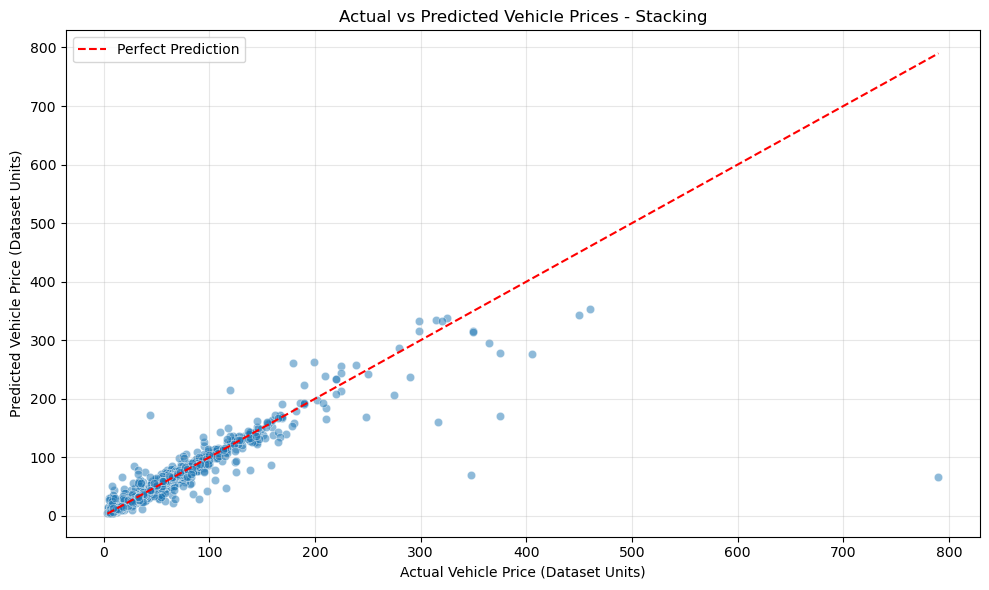

In [42]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_test,
    y=stacking_predictions,
    alpha=0.5
)

min_price = min(
    y_test.min(),
    stacking_predictions.min()
)

max_price = max(
    y_test.max(),
    stacking_predictions.max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted Vehicle Prices - Stacking')
plt.xlabel('Actual Vehicle Price (Dataset Units)')
plt.ylabel('Predicted Vehicle Price (Dataset Units)')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Actual vs. Predicted Vehicle Price Analysis

A scatter plot was generated to compare actual vehicle prices with the predictions produced by the Stacking Regressor. A diagonal reference line was included to represent perfect predictions, where the actual and predicted prices are equal.

Points close to the reference line indicate accurate predictions, while points farther away represent larger prediction errors. This visualization helps assess the model's predictive accuracy, identify overestimations and underestimations, and examine its performance across different vehicle price ranges.

The analysis complements the previously calculated MAE, RMSE, and R² evaluation metrics.

# Residual Error Analysis for the Stacking Model

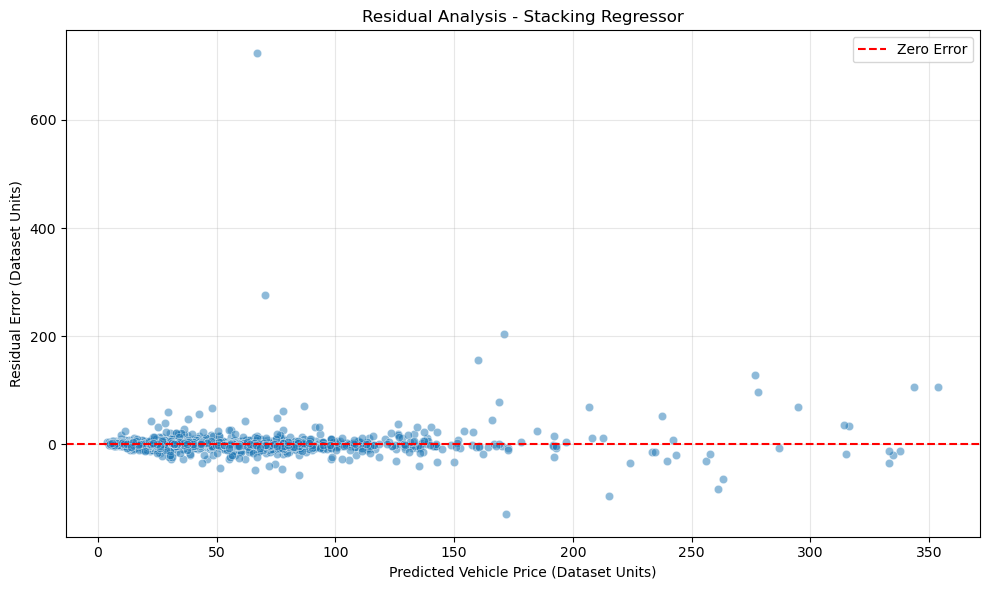

In [43]:
# Calculate residual errors
stacking_residuals = (
    y_test.to_numpy() - stacking_predictions
)

# Create residual plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=stacking_predictions,
    y=stacking_residuals,
    alpha=0.5
)

# Add reference line at zero
plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

plt.title('Residual Analysis - Stacking Regressor')
plt.xlabel('Predicted Vehicle Price (Dataset Units)')
plt.ylabel('Residual Error (Dataset Units)')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:

import joblib

# Save the trained Stacking model
joblib.dump(
    stacking_model,
    'stacking_model.pkl'
)

# Save the fitted preprocessing transformer
joblib.dump(
    preprocessor,
    'preprocessor.pkl'
)

# Save the original feature column names
joblib.dump(
    X_train.columns.tolist(),
    'feature_columns.pkl'
)

print("Stacking model saved successfully!")
print("Preprocessor saved successfully!")
print("Feature columns saved successfully!")

Stacking model saved successfully!
Preprocessor saved successfully!
Feature columns saved successfully!


In [45]:
loaded_model = joblib.load('stacking_model.pkl')
loaded_preprocessor = joblib.load('preprocessor.pkl')
loaded_columns = joblib.load('feature_columns.pkl')

X_test_loaded = loaded_preprocessor.transform(
    X_test[loaded_columns]
)

loaded_predictions = loaded_model.predict(
    X_test_loaded
)

import numpy as np

print(
    "Predictions match:",
    np.allclose(
        stacking_predictions,
        loaded_predictions
    )
)


Predictions match: True


# Test the saved model with vehicle data

In [46]:
sample_vehicle = X_test.iloc[[0]]

print("Vehicle Information:")
display(sample_vehicle)

sample_processed = loaded_preprocessor.transform(
    sample_vehicle[loaded_columns]
)

predicted_price = loaded_model.predict(
    sample_processed
)[0]

actual_price = y_test.iloc[0]

print(f"Predicted Price: {predicted_price:.2f}")
print(f"Actual Price: {actual_price:.2f}")
print(f"Absolute Error: {abs(actual_price - predicted_price):.2f}")

Vehicle Information:


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW
1744,MERCEDES-BENZ,E220 CDI,2017,2200.0,Automatic,Diesel,88000.0,Colombo,No Leasing,USED,Available,Available,Available,Available


Predicted Price: 278.10
Actual Price: 375.00
Absolute Error: 96.90
